# Can a finite loss still have nonfinite gradients?

**Question:** Within a chosen input range and dtype, how can we search for a loss
that returns NaN or infinity in forward **or** backward?

At `x = 0`, `sqrt(x)` returns exactly `0`, but its gradient is infinite.
We will make that distinction visible, then run a time-budgeted Monte Carlo
check that **continues after failures** and returns aggregate evidence.

The demonstrated losses stay in the notebook. The reusable testing machinery
is installed as `ml_sandbox.numerical_finiteness`, so the same API can be used in
another project. It evaluates scalar losses and checks every input marked
`requires_grad=True`.

In [1]:
from dataclasses import dataclass
from datetime import timedelta
from typing import TypedDict

import altair as alt
import torch
import vl_convert as vlc
from IPython.display import SVG, display
from rich.console import Console
from rich.table import Table
from torch import Tensor

from ml_sandbox.numerical_finiteness import (
    Absent,
    FinitenessReport,
    Sample,
    check_finiteness,
)

console = Console(force_jupyter=True, width=100)
torch.set_printoptions(precision=8)

## 1. Inspect one input before running thousands

Our domain is `0 <= x <= 1`. The controlled change is to add a positive epsilon
inside the square root. This changes the loss; it is not a numerically identical
replacement. Both formulas and their gradients remain directly inspectable.

In [2]:
EPSILON = 1e-6


def original_loss(x: Tensor) -> Tensor:
    """Preserve the square root's derivative singularity at zero."""
    return x.sqrt()


def regularized_loss(x: Tensor) -> Tensor:
    """Shift the square root away from its singularity on nonnegative inputs."""
    return (x + EPSILON).sqrt()


x = torch.tensor(0.0, dtype=torch.float32, requires_grad=True)
original = original_loss(x)
original_gradient = torch.autograd.grad(original, x)[0]
regularized = regularized_loss(x)
regularized_gradient = torch.autograd.grad(regularized, x)[0]

console.print(f"x = {x.item()}")
console.print(f"sqrt(x): loss = {original.item()}, gradient = {original_gradient.item()}")
console.print(
    f"sqrt(x + ε): loss = {regularized.item():.6g}, gradient = {regularized_gradient.item():.6g}"
)
assert torch.isfinite(original)
assert torch.isinf(original_gradient)
assert torch.isfinite(regularized) and torch.isfinite(regularized_gradient)

x = 0.0

sqrt(x): loss = 0.0, gradient = inf

sqrt(x + ε): loss = 0.001, gradient = 500

## 2. See why forward checks alone miss the failure

Read the aligned panels from top to bottom. The losses look almost identical
away from zero, while their gradients behave very differently near zero.
The red vertical line marks a nonfinite gradient; infinity is deliberately
**not** plotted as a finite y-coordinate.

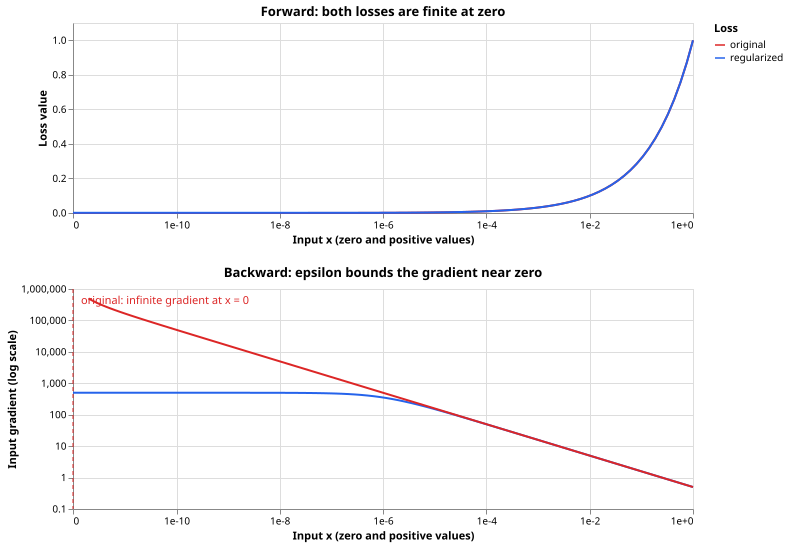

In [3]:
class CurveRow(TypedDict):
    """One finite value in the aligned forward/backward visualization."""

    x: float
    variant: str
    metric: str
    value: float


curve_rows: list[CurveRow] = []
curve_inputs = torch.cat((torch.zeros(1), torch.logspace(-12, 0, 100)))
for input_value in curve_inputs:
    for variant, loss_fn in (("original", original_loss), ("regularized", regularized_loss)):
        leaf = input_value.detach().clone().requires_grad_()
        value = loss_fn(leaf)
        gradient = torch.autograd.grad(value, leaf)[0]
        for metric, measured in (("loss", value), ("gradient", gradient)):
            if bool(torch.isfinite(measured)):
                curve_rows.append(
                    {
                        "x": leaf.item(),
                        "variant": variant,
                        "metric": metric,
                        "value": measured.item(),
                    }
                )

colors = alt.Scale(domain=["original", "regularized"], range=["#dc2626", "#2563eb"])
x_axis = alt.X(
    "x:Q",
    title="Input x (zero and positive values)",
    scale=alt.Scale(type="symlog", constant=1e-12, domain=[0, 1]),
    axis=alt.Axis(
        values=[0, 1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1],
        labelExpr="datum.value === 0 ? '0' : format(datum.value, '.0e')",
    ),
)
curve = (
    alt.Chart(alt.Data(values=curve_rows))
    .mark_line()
    .encode(
        x=x_axis,
        color=alt.Color("variant:N", scale=colors, title="Loss"),
    )
)
forward_chart = (
    curve.transform_filter(alt.datum.metric == "loss")
    .encode(
        y=alt.Y("value:Q", title="Loss value"),
    )
    .properties(width=620, height=190, title="Forward: both losses are finite at zero")
)
backward_curve = curve.transform_filter(alt.datum.metric == "gradient").encode(
    y=alt.Y(
        "value:Q",
        title="Input gradient (log scale)",
        scale=alt.Scale(type="log"),
        axis=alt.Axis(values=[0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]),
    ),
)
zero_data = alt.Data(values=[{"x": 0, "label": "original: infinite gradient at x = 0"}])
zero_rule = alt.Chart(zero_data).mark_rule(color="#dc2626", strokeDash=[4, 3]).encode(x=x_axis)
zero_label = (
    alt.Chart(zero_data)
    .mark_text(
        color="#dc2626",
        align="left",
        dx=8,
    )
    .encode(x=x_axis, y=alt.value(12), text="label:N")
)
backward_chart = (backward_curve + zero_rule + zero_label).properties(
    width=620,
    height=220,
    title="Backward: epsilon bounds the gradient near zero",
)
display(SVG(vlc.vegalite_to_svg(alt.vconcat(forward_chart, backward_chart).to_dict())))

For positive inputs, the original derivative is `1 / (2 * sqrt(x))`.
The regularized derivative is `1 / (2 * sqrt(x + ε))`, so its mathematical
maximum on this domain is **500** when `ε = 1e-6`. Floating-point rounding
changes that value slightly, especially in float16.

We verify the plotted derivatives against these formulas at positive float32
inputs. This is a separate check from searching for nonfinite values.

In [4]:
positive = torch.logspace(-12, 0, 20, dtype=torch.float32, requires_grad=True)
original_gradients = torch.autograd.grad(original_loss(positive).sum(), positive)[0]
regularized_gradients = torch.autograd.grad(regularized_loss(positive).sum(), positive)[0]
torch.testing.assert_close(original_gradients, 0.5 / positive.detach().sqrt())
torch.testing.assert_close(regularized_gradients, 0.5 / (positive.detach() + EPSILON).sqrt())

## 3. Choose a sampling distribution that can expose the boundary

Uniform random draws alone rarely hit exact zero. We check five deterministic
inputs first: `0`, `1e-12`, `1e-8`, `1e-4`, and `1`.

Then each random trial selects one of three strategies:

- **25% exact zero**, to exercise the known singularity repeatedly.
- **25% logarithmically distributed values** from `1e-12` to `1e-2`.
- **50% uniform values** from `0` to `1`.

Samples are drawn using the supplied seeded CPU generator, then cast to the
chosen dtype. Tiny float16 inputs can round to zero, making precision part
of the experiment. Every representable sampled input stays in `[0, 1]`.

In [5]:
@dataclass(frozen=True)
class BoundedSampler:
    """Make sampling precision and placement explicit while labeling each distribution."""

    dtype: torch.dtype
    device: torch.device

    def __call__(self, generator: torch.Generator) -> Sample:
        """Draw one bounded input using only the supplied random generator."""
        strategy_draw = int(torch.randint(4, (), generator=generator).item())
        match strategy_draw:
            case 0:
                strategy = "exact_zero"
                value = torch.tensor(0.0)
            case 1:
                strategy = "near_zero"
                exponent = -12 + 10 * torch.rand((), generator=generator)
                value = 10.0**exponent
            case _:
                strategy = "uniform"
                value = torch.rand((), generator=generator)
        inputs = (value.to(dtype=self.dtype, device=self.device).requires_grad_(),)
        return Sample(inputs=inputs, strategy=strategy)


CPU = torch.device("cpu")
boundary_values = (0.0, 1e-12, 1e-8, 1e-4, 1.0)
float16_boundaries = [torch.tensor(value, dtype=torch.float16).item() for value in boundary_values]
console.print(f"Requested boundaries: {boundary_values}")
console.print(f"After float16 rounding: {float16_boundaries}")
assert float16_boundaries[:3] == [0.0, 0.0, 0.0]

Requested boundaries: (0.0, 1e-12, 1e-08, 0.0001, 1.0)

After float16 rounding: [0.0, 0.0, 0.0, 0.00010001659393310547, 1.0]

## 4. Run until the deadline, continuing after every failure

A one-second budget keeps this notebook quick. Change `budget` to
`timedelta(seconds=60)` for a longer run. Boundaries and random trials share
the budget; the report shows how many boundaries actually completed.

`max_examples=3` limits saved tensor evidence, **not** failure counts. Saved examples
favor different failure groups instead of filling the cap with one repeated case.
`required_gradients=(0,)` declares that this loss must remain connected to its input.

The notebook uses `quiet=True` to keep saved output static and compact; ordinary calls
show progress by default. Counts vary with machine speed, even though the seed
reproduces the random input prefix.

In [6]:
@dataclass(frozen=True)
class Run:
    """Attach experiment labels to a tester report."""

    variant: str
    dtype: str
    report: FinitenessReport


budget = timedelta(seconds=1)
runs: list[Run] = []
for dtype in (torch.float32, torch.float16):
    boundaries = [
        (torch.tensor(value, dtype=dtype, device=CPU, requires_grad=True),)
        for value in boundary_values
    ]
    for variant, loss_fn in (("original", original_loss), ("regularized", regularized_loss)):
        dtype_name = str(dtype).removeprefix("torch.")
        console.print(f"Testing {variant} in {dtype_name} for {budget.total_seconds():g}s")
        report = check_finiteness(
            loss_fn,
            BoundedSampler(dtype=dtype, device=CPU),
            duration=budget,
            seed=42,
            boundary_inputs=boundaries,
            max_examples=3,
            required_gradients=(0,),
            quiet=True,
        )
        runs.append(Run(variant, dtype_name, report))
        assert report.boundary.trials == len(boundaries)
        assert report.random.trials > 0
        if variant == "original":
            assert report.boundary.nonfinite_gradient > 0
            assert report.random.nonfinite_gradient > len(report.examples)
        else:
            assert report.boundary.failed_trials == 0
            assert report.random.failed_trials == 0

Testing original in float32 for 1s

Testing regularized in float32 for 1s

Testing original in float16 for 1s

Testing regularized in float16 for 1s

## 5. Read results for each sampling strategy

Each bar is the **fraction of trials in that group** with a nonfinite loss or gradient.
Zero-percent labels remain visible even when the bar has no height. The deterministic
boundaries and each random distribution have their own row, so a combined Monte Carlo
rate cannot hide which strategy found a failure.

The original loss stays finite in forward while failing in backward. Exact-zero draws
fail in both precisions. Tiny positive inputs from the near-zero strategy can also round
to zero in float16. Uniform draws rarely find that singularity. The regularized loss
has no observed failures in these runs.

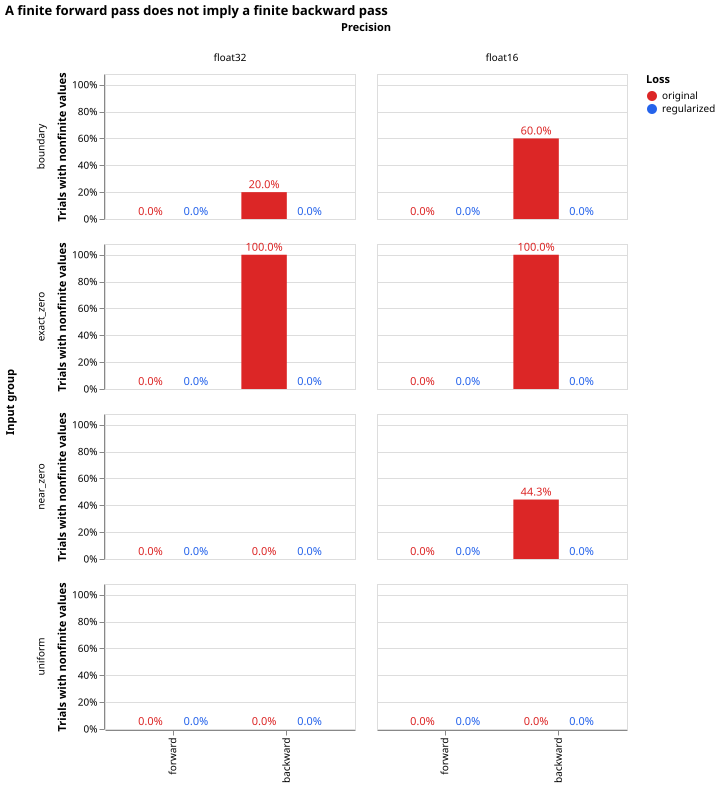

In [7]:
class RateRow(TypedDict):
    """A forward or backward nonfinite trial rate for one experiment group."""

    dtype: str
    variant: str
    source: str
    stage: str
    rate: float


rate_rows: list[RateRow] = []
for run in runs:
    for source, summary in (("boundary", run.report.boundary), *run.report.strategies.items()):
        for stage, issue in (("forward", "nonfinite_loss"), ("backward", "nonfinite_gradient")):
            rate = summary.rate(issue)
            assert isinstance(rate, float)
            rate_rows.append(
                {
                    "dtype": run.dtype,
                    "variant": run.variant,
                    "source": source,
                    "stage": stage,
                    "rate": rate,
                }
            )

base = alt.Chart(alt.Data(values=rate_rows)).encode(
    x=alt.X("stage:N", sort=["forward", "backward"], title=None),
    xOffset=alt.XOffset("variant:N", sort=["original", "regularized"]),
    y=alt.Y(
        "rate:Q",
        title="Trials with nonfinite values",
        axis=alt.Axis(format="%"),
        scale=alt.Scale(domain=[0, 1.08]),
    ),
    color=alt.Color("variant:N", scale=colors, title="Loss"),
)
bars = base.mark_bar()
labels = base.mark_text(dy=-7, color="#111827").encode(text=alt.Text("rate:Q", format=".1%"))
failure_chart = (
    (bars + labels)
    .properties(width=250, height=145)
    .facet(
        row=alt.Row(
            "source:N", sort=["boundary", "exact_zero", "near_zero", "uniform"], title="Input group"
        ),
        column=alt.Column("dtype:N", sort=["float32", "float16"], title="Precision"),
    )
    .properties(title="A finite forward pass does not imply a finite backward pass")
)
display(SVG(vlc.vegalite_to_svg(failure_chart.to_dict())))

The table provides exact per-group counts and finite extrema, supplementing the chart.
Maxima exclude NaN and infinity; an unavailable maximum has an explicit reason instead
of a misleading zero. `report.random` remains available as the combined random summary.

Exception and missing-required-gradient counts are also available. Issue categories
overlap: a trial can fail in both forward and backward. `failed_trials` counts each
affected trial once. `losses_checked` and `gradient_trials_checked` show whether those
stages produced evidence. Optional disconnected inputs are coverage information;
they are failures only when the caller explicitly requires their gradients.

In [8]:
def show_maximum(value: float | Absent) -> str:
    """Format a finite maximum or its absence reason for exact-value evidence."""
    match value:
        case float():
            return f"{value:.6g}"
        case Absent(reason=reason):
            return reason


table = Table(title="Exact evidence by input group: all failures counted")
for column in (
    "loss / dtype",
    "source",
    "trials",
    "failed",
    "NaN/Inf loss",
    "NaN/Inf grad",
    "max |loss|",
    "max |grad|",
):
    table.add_column(column)
for run in runs:
    for source, summary in (("boundary", run.report.boundary), *run.report.strategies.items()):
        table.add_row(
            f"{run.variant} / {run.dtype}",
            source,
            str(summary.trials),
            str(summary.failed_trials),
            str(summary.nonfinite_loss),
            str(summary.nonfinite_gradient),
            show_maximum(summary.max_abs_loss),
            show_maximum(summary.max_abs_gradient),
        )
    console.print(
        f"{run.variant} / {run.dtype}: {run.report.trials} trials in "
        f"{run.report.elapsed.total_seconds():.3f}s; {len(run.report.examples)} saved failures"
    )
console.print(table)

original / float32: 29021 trials in 1.000s; 3 saved failures

regularized / float32: 27358 trials in 1.000s; 0 saved failures

original / float16: 29063 trials in 1.000s; 3 saved failures

regularized / float16: 27302 trials in 1.000s; 0 saved failures

                        Exact evidence by input group: all failures counted                         
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ loss /      ┃            ┃        ┃        ┃ NaN/Inf     ┃ NaN/Inf    ┃            ┃             ┃
┃ dtype       ┃ source     ┃ trials ┃ failed ┃ loss        ┃ grad       ┃ max |loss| ┃ max |grad|  ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ original /  │ boundary   │ 5      │ 1      │ 0           │ 1          │ 1          │ 500000      │
│ float32     │            │        │        │             │            │            │             │
│ original /  │ uniform    │ 14543  │ 0      │ 0           │ 0          │ 0.999965   │ 82.4494     │
│ float32     │            │        │        │             │            │            │             │
│ original /  │ exact_zero │ 7383   │ 7383   │ 0           │ 7383       │ 0          │ no finite   │
│ float32     │            │        │        │             │            │            │ gradient    │
│             │            │        │        │             │            │            │ elements    │
│ original /  │ near_zero  │ 7090   │ 0      │ 0           │ 0          │ 0.0999088  │ 499074      │
│ float32     │            │        │        │             │            │            │             │
│ regularized │ boundary   │ 5      │ 0      │ 0           │ 0          │ 1          │ 500         │
│ / float32   │            │        │        │             │            │            │             │
│ regularized │ uniform    │ 13718  │ 0      │ 0           │ 0          │ 0.999966   │ 81.3508     │
│ / float32   │            │        │        │             │            │            │             │
│ regularized │ exact_zero │ 6961   │ 0      │ 0           │ 0          │ 0.001      │ 500         │
│ / float32   │            │        │        │             │            │            │             │
│ regularized │ near_zero  │ 6674   │ 0      │ 0           │ 0          │ 0.0999138  │ 500         │
│ / float32   │            │        │        │             │            │            │             │
│ original /  │ boundary   │ 5      │ 3      │ 0           │ 3          │ 1          │ 50          │
│ float16     │            │        │        │             │            │            │             │
│ original /  │ uniform    │ 14569  │ 0      │ 0           │ 0          │ 1          │ 82.4375     │
│ float16     │            │        │        │             │            │            │             │
│ original /  │ exact_zero │ 7390   │ 7390   │ 0           │ 7390       │ 0          │ no finite   │
│ float16     │            │        │        │             │            │            │ gradient    │
│             │            │        │        │             │            │            │ elements    │
│ original /  │ near_zero  │ 7099   │ 3144   │ 0           │ 3144       │ 0.0999146  │ 2048        │
│ float16     │            │        │        │             │            │            │             │
│ regularized │ boundary   │ 5      │ 0      │ 0           │ 0          │ 1          │ 496.5       │
│ / float16   │            │        │        │             │            │            │             │
│ regularized │ uniform    │ 13681  │ 0      │ 0           │ 0          │ 1          │ 81.375      │
│ / float16   │            │        │        │             │            │            │             │
│ regularized │ exact_zero │ 6949   │ 0      │ 0           │ 0          │ 0.00100708 │ 496.5       │
│ / float16   │            │        │        │             │            │            │             │
│ regularized │ near_zero  │ 6667   │ 0      │ 0           │ 0          │ 0.0999146  │ 496.5       │
│ / float16   │            │        │        │             │            │            │             │
└─────────────┴────────────┴────────┴────────┴─────────────┴─

## 6. Reproduce a saved failure

Saved examples contain detached CPU copies, original devices, gradient flags,
the sampling strategy, a zero-based index within the boundary or random source,
and failure categories. `replay_inputs()` creates fresh leaves in the original
dtype/device. Evidence retention favors distinct groups within the storage cap.
Every later failure still contributes to aggregate counts.

In [9]:
original_report = runs[0].report
failure = original_report.examples[0]
replay = failure.replay_inputs()
replay_loss = original_loss(*replay)
replay_gradient = torch.autograd.grad(replay_loss, replay)[0]

console.print(
    f"Source: {failure.source}; trial index: {failure.trial_index}; seed: {original_report.seed}"
)
console.print(f"Strategy: {failure.strategy}; issues: {failure.issues}; input: {replay[0].item()}")
console.print(f"Replayed loss: {replay_loss.item()}; gradient: {replay_gradient.item()}")
console.print(
    f"Total backward failures: {original_report.boundary.nonfinite_gradient + original_report.random.nonfinite_gradient}; "
    f"saved examples: {len(original_report.examples)}"
)
assert torch.isfinite(replay_loss) and torch.isinf(replay_gradient)

Source: boundary; trial index: 0; seed: 42

Strategy: boundary; issues: ('nonfinite_gradient',); input: 0.0

Replayed loss: 0.0; gradient: inf

Total backward failures: 7384; saved examples: 3

## 7. Use a fixed trial count for regression checks

A time budget is convenient for exploration. A fixed trial count and seed give the same
sampled input prefix across runs, making a regression check repeatable. Here the five
boundaries count toward the total of 256 trials. Combining both limits stops at whichever
is reached first; `stop_reason` records which limit ended the run.

In [10]:
fixed_report = check_finiteness(
    regularized_loss,
    BoundedSampler(dtype=torch.float32, device=CPU),
    max_trials=256,
    seed=42,
    boundary_inputs=[
        (torch.tensor(value, dtype=torch.float32, requires_grad=True),) for value in boundary_values
    ],
    required_gradients=(0,),
    quiet=True,
)
assert fixed_report.trials == 256
assert fixed_report.boundary.trials == 5
assert fixed_report.random.trials == 251
assert fixed_report.stop_reason == "max_trials"
assert fixed_report.boundary.failed_trials == fixed_report.random.failed_trials == 0
console.print(
    f"Fixed-count run: {fixed_report.trials} trials; stopped by {fixed_report.stop_reason}"
)

Fixed-count run: 256 trials; stopped by max_trials

## 8. Apply the installed API to your own loss

Import `check_finiteness` from `ml_sandbox.numerical_finiteness` in another project.
Replace the loss function and sampler. Return positional tensor arguments as a tuple,
or wrap them in `Sample(inputs, strategy)` to label their distribution. Mark every input
whose gradient matters with `requires_grad=True`. Constant targets may remain
nondifferentiable. Return a scalar loss with an explicit reduction. For model parameter
gradients, expose parameters as differentiated arguments rather than hiding them in a
closure. Supply relevant boundary cases and test the shapes, precision, and device
you actually intend to use.

The tester copies inputs to fresh independent leaves and uses `autograd.grad`, so it
preserves caller `.grad` fields. It records forward/backward exceptions and continues.
Sampler errors and invalid input tuples propagate because they violate the setup.
Inputs must be finite and at least one argument must require gradients. Disconnected
inputs are reported separately; `required_gradients` identifies which missing gradients
are failures. `gradient_scale` lets you test an incoming gradient other than one,
such as a mixed-precision loss scale.

Provide `duration`, `max_trials`, or both. The first reached limit stops the run, with
boundaries counting toward both limits. The deadline is checked between trials, so one
trial can overrun it. Reproducibility requires using the supplied generator and a
deterministic loss. Device checks synchronize when values are read.

This report measures **how often the chosen experiment encountered nonfinite losses
or input gradients**. Zero observed failures is evidence about these samples and this
precision, not a proof that the function can never fail.